In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

data = {}
for f in sorted(Path("data_clean").glob("*.csv")):
    data[f.stem] = pd.read_csv(f)

windows = pd.read_csv("data_features/windows_5m.csv")
windows = windows[windows["label"] != "left out"].copy()

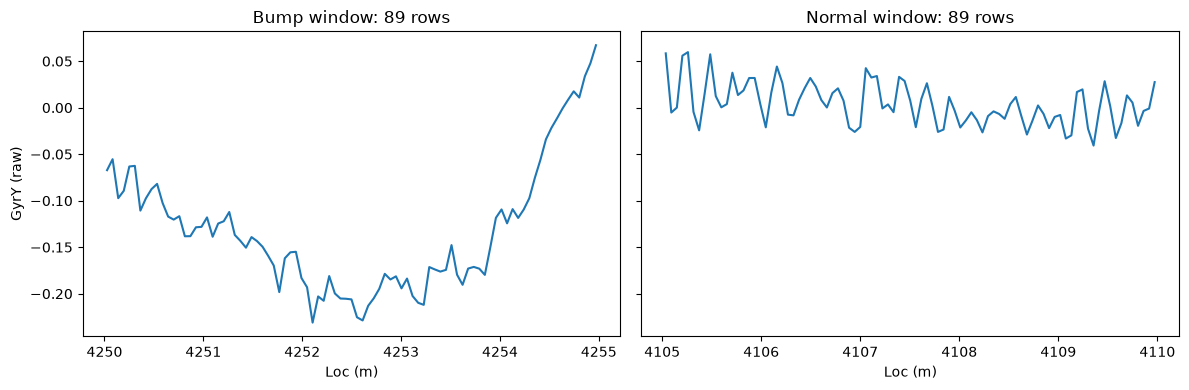

In [ ]:
# Let's visualize the raw GyrY data for a bump window and a normal window
d = data["Iisingintie_Acc1_m800_RDMC_2026-05-06_123750"].copy()
d["window"] = (d["Loc(m)"] // 5).astype(int)

m800 = windows[windows["drive"].str.contains("m800")]
bump_w = m800[m800["label"] == "bump"]["window"].iloc[5]
normal_w = m800[m800["label"] == "no bump"]["window"].iloc[50]

fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for ax, w_num, title in zip(axes, [bump_w, normal_w], ["Bump window", "Normal window"]):
    rows = d[d["window"] == w_num]
    ax.plot(rows["Loc(m)"], rows["GyrY"])
    ax.set_title(f"{title}: {len(rows)} rows")
    ax.set_xlabel("Loc (m)")
axes[0].set_ylabel("GyrY (raw)")
plt.tight_layout()
plt.show()

#### Now, two problems needs to be solved

* Different lengths. This window has about 90 rows, and at 40 km/h the same 5 m has about 170. But MiniRocket and the CNN need every window to be exactly the same length, like photos that all need the same number of pixels.

* Different scales. At 80 km/h, everything shakes more than at 40 km/h. It’s the same speed problem we solved with relative features, now for the raw signal.

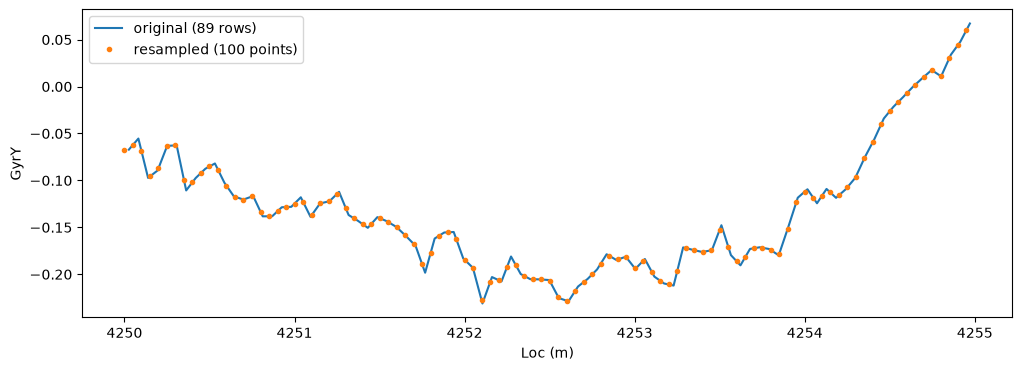

In [ ]:
# Resample one bump window to 100 points
rows = d[d["window"] == bump_w]

# Take the wind
start = bump_w * 5
positions = start + np.arange(100) * 0.05

# Resample the GyrY values to 100 points using linear interpolation
resampled = np.interp(positions, rows["Loc(m)"], rows["GyrY"])

plt.figure(figsize=(12, 4))
plt.plot(rows["Loc(m)"], rows["GyrY"], label=f"original ({len(rows)} rows)")
plt.plot(positions, resampled, "o", markersize=3, label="resampled (100 points)")
plt.xlabel("Loc (m)")
plt.ylabel("GyrY")
plt.legend()
plt.show()